In [1]:
!pip install -q torch torchvision onnx onnxruntime fastapi uvicorn pillow python-multipart httpx scikit-learn

In [2]:
import torch
import torch.nn as nn
import torch.optim as optim

import numpy as np
import onnx
import onnxruntime as ort

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split

from torch.utils.data import TensorDataset, DataLoader

import matplotlib.pyplot as plt
import time
import io

from PIL import Image
from fastapi import FastAPI, UploadFile, File
from fastapi.testclient import TestClient

# Load dataset
digits = load_digits()

X = digits.images.astype(np.float32) / 16.0
y = digits.target.astype(np.int64)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Use only 1000 training images
X_train = X_train[:1000]
y_train = y_train[:1000]

# Convert to tensors
X_train = torch.tensor(X_train).unsqueeze(1)
y_train = torch.tensor(y_train)

X_test = torch.tensor(X_test).unsqueeze(1)
y_test = torch.tensor(y_test)

train_data = TensorDataset(X_train, y_train)

train_loader = DataLoader(
    train_data, batch_size=32, shuffle=True
)

print("Dataset loaded successfully")
print("Training images:", len(X_train))
print("Image size: 8 x 8")

Dataset loaded successfully
Training images: 1000
Image size: 8 x 8


In [3]:
class VisionModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Conv2d(1, 8, 3),
            nn.ReLU(),
            nn.Flatten(),
            nn.Linear(8 * 6 * 6, 10)
        )

    def forward(self, x):
        return self.network(x)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = VisionModel().to(device)

loss_function = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(), lr=0.001
)

# Training
for epoch in range(5):

    total_loss = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        "Epoch:", epoch + 1,
        "Loss:", round(total_loss / len(train_loader), 4)
    )

print("Model training completed")

Epoch: 1 Loss: 2.1568
Epoch: 2 Loss: 1.739
Epoch: 3 Loss: 1.2387
Epoch: 4 Loss: 0.8442
Epoch: 5 Loss: 0.5963
Model training completed


In [4]:
model.eval()

dummy_input = torch.randn(
    1, 1, 8, 8
).to(device)

torch.onnx.export(
    model,
    dummy_input,
    "vision_model.onnx",
    input_names=["input"],
    output_names=["output"],
    opset_version=17,
    dynamo=False
)

print("ONNX model exported successfully")

onnx_model = onnx.load("vision_model.onnx")
onnx.checker.check_model(onnx_model)

print("ONNX model validation successful")

/tmp/ipykernel_2345/1540008278.py:7: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX model exported successfully
ONNX model validation successful


In [5]:
session = ort.InferenceSession("vision_model.onnx")

input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

print("ONNX Model Loaded Successfully")
print("Input:", input_name)
print("Output:", output_name)

ONNX Model Loaded Successfully
Input: input
Output: output


In [6]:
app = FastAPI()

@app.get("/")
def home():
    return {"message": "VisionPort API Running"}

print("FastAPI Application Created")

FastAPI Application Created


In [7]:
@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    print("\n===== INFERENCE REQUEST TRACE =====")

    # 1. API INPUT
    print("\n1. API INPUT")

    image_bytes = await file.read()

    print("Filename:", file.filename)
    print("Image received successfully")

    # 2. PREPROCESSING
    print("\n2. IMAGE PREPROCESSING")

    image = Image.open(
        io.BytesIO(image_bytes)
    ).convert("L")

    image = image.resize((8, 8))

    data = np.array(image).astype(np.float32) / 255.0

    data = data.reshape(1, 1, 8, 8)

    print("Grayscale conversion completed")
    print("Image resized to 8 x 8")
    print("Normalization completed")

    # 3. MODEL EXECUTION
    print("\n3. ONNX MODEL EXECUTION")

    start = time.time()

    result = session.run(
        [output_name],
        {input_name: data}
    )

    end = time.time()

    digit = int(np.argmax(result[0]))

    inference_time = (end - start) * 1000

    print("Model execution completed")
    print("Predicted digit:", digit)
    print("Inference time:", round(inference_time, 2), "ms")

    # 4. API RESPONSE
    print("\n4. API RESPONSE")

    return {
        "filename": file.filename,
        "prediction": digit,
        "inference_time_ms": round(inference_time, 2),
        "status": "success"
    }

In [8]:
client = TestClient(app)

response = client.get("/")

print("API Status:", response.status_code)
print("API Response:", response.json())

API Status: 200
API Response: {'message': 'VisionPort API Running'}


In [9]:
# Select test image
test_image = X_test[0].squeeze().numpy()

actual_digit = int(y_test[0])

# Convert into image
image_array = (test_image * 255).astype(np.uint8)

buffer = io.BytesIO()

Image.fromarray(image_array).save(
    buffer, format="PNG"
)

# Send API request
response = client.post(
    "/predict",
    files={
        "file": (
            "test_digit.png",
            buffer.getvalue(),
            "image/png"
        )
    }
)

print("\nActual Digit:", actual_digit)
print("API Status:", response.status_code)
print("Final API Response:")
print(response.json())


===== INFERENCE REQUEST TRACE =====

1. API INPUT
Filename: test_digit.png
Image received successfully

2. IMAGE PREPROCESSING
Grayscale conversion completed
Image resized to 8 x 8
Normalization completed

3. ONNX MODEL EXECUTION
Model execution completed
Predicted digit: 5
Inference time: 0.24 ms

4. API RESPONSE

Actual Digit: 5
API Status: 200
Final API Response:
{'filename': 'test_digit.png', 'prediction': 5, 'inference_time_ms': 0.24, 'status': 'success'}


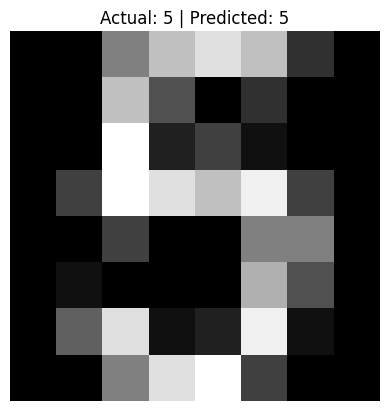

In [10]:
plt.imshow(test_image, cmap="gray")

plt.title(
    f"Actual: {actual_digit} | "
    f"Predicted: {response.json()['prediction']}"
)

plt.axis("off")
plt.show()

In [11]:
loss_history = []
accuracy_history = []

for epoch in range(5):

    total_loss = 0
    correct = 0
    total = 0

    model.train()

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = loss_function(outputs, labels)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

        predictions = torch.argmax(outputs, dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    avg_loss = total_loss / len(train_loader)
    accuracy = 100 * correct / total

    loss_history.append(avg_loss)
    accuracy_history.append(accuracy)

    print("Epoch:", epoch + 1)
    print("Loss:", round(avg_loss, 4))
    print("Accuracy:", round(accuracy, 2), "%")

print("Training completed!")

Epoch: 1
Loss: 0.4662
Accuracy: 93.0 %
Epoch: 2
Loss: 0.3915
Accuracy: 93.4 %
Epoch: 3
Loss: 0.3244
Accuracy: 93.9 %
Epoch: 4
Loss: 0.2872
Accuracy: 94.2 %
Epoch: 5
Loss: 0.2621
Accuracy: 94.8 %
Training completed!


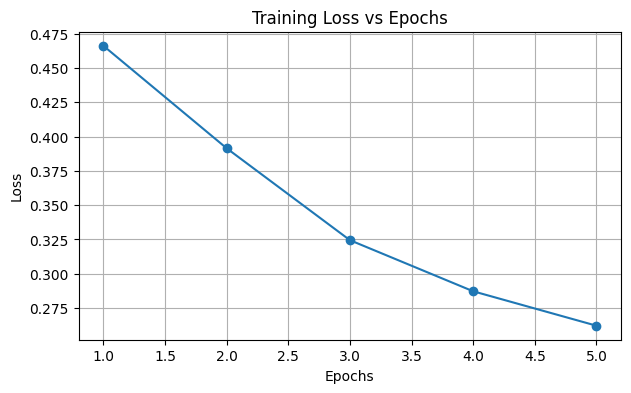

In [12]:
plt.figure(figsize=(7, 4))

plt.plot(range(1, 6), loss_history, marker="o")

plt.title("Training Loss vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.grid(True)

plt.show()

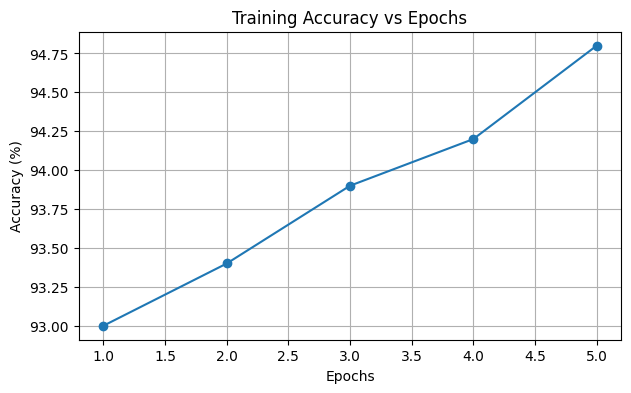

In [13]:
plt.figure(figsize=(7, 4))

plt.plot(range(1, 6), accuracy_history, marker="o")

plt.title("Training Accuracy vs Epochs")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")
plt.grid(True)

plt.show()